In [1]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import spacy

nlp = spacy.load("it_core_news_sm")

In [2]:
query_df = pd.read_csv("Data/query_formulation_df.csv")
serp_df = pd.read_csv("Data/logs_compiled.csv")
queries = pd.read_csv("Data/query_df.csv")
query_df["qid"] = [serp_df.loc[serp_df["serp_id"]==serp_id]["qid"].values[0] for serp_id in query_df["serp_id"]]
query_df["timestamp"] = [queries.loc[queries["qid"]==qid]["timestamp"].values[0] for qid in query_df["qid"]]
query_df = query_df[["uid","topic_number","qid","query", "timestamp", "serp_id", "precision@10"]]
query_df.to_csv("Data/query_formulation_df.csv", index=False, encoding="utf8")
query_df.head(10)

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,2026-05-19 14:51:26.583,serp1,0.2
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,2026-05-19 15:02:41.120,serp2,0.1
2,1,g3t1,q3,Fiume sacro degli indiani,2026-05-19 15:08:39.525,serp3,0.4
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,2026-05-19 14:51:20.189,serp5,0.2
5,2,g3t2,q6,Qual è il nome del simbolo al centro della ban...,2026-05-19 15:05:41.521,serp6,0.3
6,2,g3t1,q8,Come si chiama il fiume sacro agli indiani,2026-05-19 15:14:10.201,serp8,0.4
7,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,2026-05-19 15:09:06.317,serp7,0.3
8,3,g3t2,q12,qual è il nome del centro della bandiera indiana,2026-05-19 15:08:18.420,serp12,0.3
9,3,g3t1,q9,come si chiama il fiume sacro agli indiani,2026-05-19 14:50:09.786,serp9,0.4


In [3]:
query_df_sample = query_df.sample(5, random_state=67).sort_index()
query_df_sample

,uid,topic_number,qid,query,timestamp,serp_id,precision@10
3,2,g3t3,q4,Quali sono i animali dall'India,2026-05-19 14:50:22.081,serp4,0.7
25,5,g3t2,q32,Bandiera,2026-05-19 15:21:16.565,serp32,0.3
38,8,g3t1,q53,Fiume sacro India,2026-05-19 15:16:17.475,serp53,0.8
77,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,2026-05-19 10:44:45.385,serp91,0.3
99,18,g3t2,q117,Simbolo della bandiera dell'india,2026-05-19 15:13:42.292,serp117,0.7


In [4]:
serp_df = pd.read_csv("Data/logs_compiled.csv")
serp_df.loc[serp_df["serp_id"]=="serp91"]
# serp_df.iloc[710]["url"]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp
709,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.storicang.it/foto-del-giorno/laika...,"Laika, il primo animale nello spazio - Storica...","\n Nov 3, 2022 ... È probabilmente la...",1.0,1,0,2026-05-19 10:44:46.556
710,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.nationalgeographic.it/spazio/2021/...,Animali e uomini nello spazio: le foto che han...,"\n Aug 9, 2021 ... La scimmia saimiri...",2.0,1,0,2026-05-19 10:44:46.558
711,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focus.it/scienza/spazio/la-storia-...,"La storia dimenticata di Félicette, il primo g...","\n Nov 11, 2017 ... Il cane Laika, lo...",3.0,1,0,2026-05-19 10:44:46.559
712,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/tecnologia/tecnolog...,Tecnologia: il primo Smartphone della storia -...,"\n Jun 4, 2015 ... Si chiama SIMON ed...",4.0,0,0,2026-05-19 10:44:46.565
713,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/news/come-funzionan...,Come funzionano i viaggi spaziali - FocusJunio...,"\n Aug 1, 2023 ... Poi è stato adotta...",5.0,0,0,2026-05-19 10:44:46.567
714,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/senza-categoria/twi...,Twitter: dal primo cinguettio al social che ha...,"\n Jul 15, 2025 ... Come è nato Twitt...",6.0,0,0,2026-05-19 10:44:46.569
715,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/news/come-funziona-...,Come funziona un conclave e quali rigide regol...,\n Il conclave è la riunione di cardi...,7.0,0,0,2026-05-19 10:44:46.570
716,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/news/alla-scoperta-...,Alla scoperta del mondo: i grandi viaggiatori ...,"\n Al di là dei monumenti, il bello d...",8.0,0,0,2026-05-19 10:44:46.571
717,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/scienza/guglielmo-m...,"Guglielmo Marconi, storia dell'uomo che ha inv...","\n Sep 19, 2024 ... ... si propagano ...",9.0,0,0,2026-05-19 10:44:46.573
718,15,g4t2,q91,Qual è stato il primo animale nello spazio e c...,serp91,https://www.focusjunior.it/news/news-e-curiosi...,Chi ha inventato i musei? - FocusJunior.it,\n ... primo museo nel 530 a.C. Si ch...,10.0,0,0,2026-05-19 10:44:46.575


In [5]:
query_len = []
for _, row in query_df.iterrows():
    query_len.append(len(row["query"].split(" ")))

query_df["query_len"] = query_len

In [6]:
query_df["effective_query"] = [int(p10 >= 0.8) for p10 in query_df["precision@10"]]

In [7]:
query_df.loc[query_df["effective_query"]==1]

,uid,topic_number,qid,query,timestamp,serp_id,precision@10,query_len,effective_query
17,4,g3t1,q18,Fiume sacro indiano,2026-05-19 15:20:20.872,serp18,0.8,3,1
38,8,g3t1,q53,Fiume sacro India,2026-05-19 15:16:17.475,serp53,0.8,3,1
39,8,g3t1,q52,Fiume sacro India,2026-05-19 15:16:00.828,serp52,0.8,3,1


<Axes: xlabel='effective_query', ylabel='query_len'>

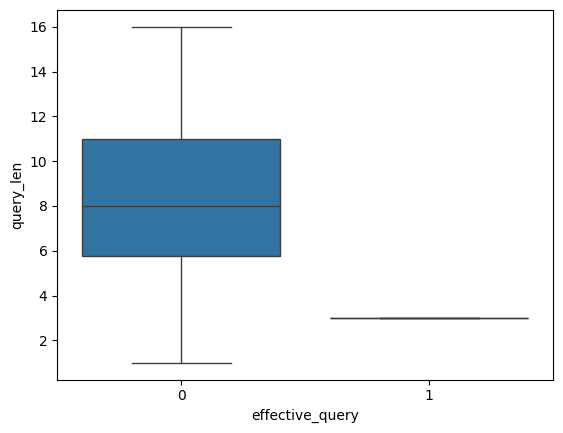

In [8]:
sns.boxplot(data=query_df, x="effective_query", y="query_len")

In [9]:
ITaoa = pd.read_excel("Resources/ItAoA_database.xlsx")
ITaoa.head()

,Ita_Word,Eng_Word,WordClass,M_AoA,SD_AoA,#L,WF_LaRepubblica,WF_ItWaC,WF_Subtlex,#OrtNB,M_WF_OrtNB,MaxWF_OrtNB,OLD20_Subtlex
0,abbaglio,dazzle,n,9.36,2.956349,8.0,6.347389,3.931826,3.891820,1.0,0.272586,0.272586,2.10
1,abbandonato,derelict,a,6.68,2.672702,11.0,8.624971,8.023880,8.023880,4.0,2.495203,3.001456,1.70
2,abbondanza,abundance,n,6.96,2.071232,10.0,7.718241,6.124683,6.122493,1.0,0.272586,0.272586,2.65
3,abbracciare,to hug,v,2.84,0.800000,11.0,8.896041,8.010028,6.118097,1.0,0.486563,0.486563,1.80
4,abbraccio,hug,n,4.20,1.290994,9.0,8.480529,7.415175,7.170888,2.0,1.819763,1.939287,2.05
